# Market Analysis and Stock Segmentation Using RFM
**6BUIS017W | CRM & CM With Business Intelligence | CWK1**

Study period: 1 January 2021 to 1 January 2025 (end exclusive). Benchmark: S&P 500 (`^GSPC`).

## Setup

In [1]:
%pip -q install yfinance lxml html5lib beautifulsoup4

In [2]:
from __future__ import annotations
import json
import hashlib
import sys
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
from IPython.display import display
import matplotlib.pyplot as plt
import scipy
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
import sklearn
import yfinance as yf
ROOT = Path.cwd() / 'cwk1_analysis'
DATA = ROOT / 'data'
OUT = ROOT / 'outputs'

for p in [DATA, OUT]:
    p.mkdir(parents=True, exist_ok=True)
START = '2021-01-01'
END = '2025-01-01'
SEED = 42
SOURCE = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'


plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'axes.axisbelow': True, 'grid.alpha': 0.2, 'axes.spines.top': False, 'axes.spines.right': False})

## Task 1: Data Preparation and Feature Engineering

### 1.1 Ticker selection and data acquisition

yfinance supplies daily closing prices, adjusted closing prices, trading volume, and corporate action data. Using the current list of S&P 500 constituents to analyse historical data introduces survivorship bias.


In [3]:
def write_json(path, x):
    path.write_text(json.dumps(x, indent=2, default=str), encoding='utf-8')

def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def acquisition():
    constituent_file = DATA / 'constituents.csv'
    if constituent_file.exists():
        cons = pd.read_csv(constituent_file)
    else:
        cons = pd.read_html(SOURCE, storage_options={'User-Agent': 'Mozilla/5.0'})[0]
        needed = ['Symbol', 'Security', 'GICS Sector', 'GICS Sub-Industry']
        if not all((c in cons for c in needed)):
            raise RuntimeError('Constituent page schema changed')
        cons = cons[needed].copy()
        cons['retrieved_utc'] = datetime.now(timezone.utc).isoformat()
        cons.to_csv(constituent_file, index=False)
    cons['YahooTicker'] = cons['Symbol'].str.replace('.', '-', regex=False)
    bmark = '^GSPC'
    tickers = cons['YahooTicker'].drop_duplicates().tolist()
    all_names = tickers + [bmark]
    missing = []
    for index in range(0, len(all_names), 25):
        batch = all_names[index:index + 25]
        for ticker in batch:
            path = DATA / f"{ticker.replace('^', 'INDEX_')}.csv"
            if path.exists():
                continue
            try:
                d = yf.download(ticker, start=START, end=END, interval='1d', auto_adjust=False, actions=True, progress=False, threads=False, multi_level_index=False)
                if d is None or d.empty:
                    missing.append(ticker)
                    continue
                if isinstance(d.columns, pd.MultiIndex):
                    d.columns = d.columns.get_level_values(0)
                d.index = pd.to_datetime(d.index).tz_localize(None).normalize()
                d.index.name = 'Date'
                d.to_csv(path)
            except Exception as ex:
                missing.append(ticker)
                print('DOWNLOAD FAILED', ticker, str(ex)[:150])
    benchmark_file = DATA / 'INDEX_GSPC.csv'
    if not benchmark_file.exists():
        raise RuntimeError('Benchmark unavailable: provide cached benchmark CSV or retry network access')
    return cons

def get_daily(ticker):
    path = DATA / f"{ticker.replace('^', 'INDEX_')}.csv"
    if not path.exists():
        return None
    x = pd.read_csv(path, index_col='Date', parse_dates=True)
    x.index = pd.to_datetime(x.index).tz_localize(None).normalize()
    return x.sort_index()

In [4]:
constituents = acquisition()
display(constituents.head())
print(f"Constituent records: {len(constituents):,}")
print("Constituent retrieval:", constituents['retrieved_utc'].iloc[0])
versions = {'python': sys.version.split()[0], 'pandas': pd.__version__,
            'numpy': np.__version__, 'scipy': scipy.__version__,
            'scikit-learn': sklearn.__version__, 'matplotlib': matplotlib.__version__,
            'yfinance': yf.__version__}
display(pd.Series(versions, name='Version').to_frame())
write_json(OUT / 'provenance.json', {
    'source': SOURCE, 'constituent_retrieved_utc': constituents['retrieved_utc'].iloc[0],
    'study_window': [START, END], 'versions': versions,
    'snapshot_sha256': {p.name: sha(p) for p in DATA.glob('*.csv')}
})

ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERRO

,Symbol,Security,GICS Sector,GICS Sub-Industry,retrieved_utc,YahooTicker
0,MMM,3M,Industrials,Industrial Conglomerates,2026-11-23T06:21:20.287814+00:00,MMM
1,AOS,A. O. Smith,Industrials,Building Products,2026-11-23T06:21:20.287814+00:00,AOS
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,2026-11-23T06:21:20.287814+00:00,ABT
3,ABBV,AbbVie,Health Care,Biotechnology,2026-11-23T06:21:20.287814+00:00,ABBV
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,2026-11-23T06:21:20.287814+00:00,ACN


Constituent records: 503
Constituent retrieval: 2026-11-23T06:21:20.287814+00:00


,Version
python,3.13.18
pandas,2.2.3
numpy,2.4.6
scipy,1.16.3
scikit-learn,1.6.1
matplotlib,3.10.0
yfinance,0.2.66


### 1.2 Data validation and alignment


To ensure that risk and return estimates are comparable, each share must have a complete trading history over the same period. The benchmark’s trading dates determine which sessions are expected. Shares are excluded if they have missing sessions, invalid price or volume values, or unavailable corporate action fields. Missing prices are left unfilled. Close and Volume are taken directly from Yahoo Finance. Checks on stock split dates are retained, although independent verification that the adjustments are compatible remains limited.

In [6]:
benchmark = get_daily('^GSPC')
benchmark = benchmark.loc[(benchmark.index >= START) & (benchmark.index < END)]
assert not benchmark.index.duplicated().any(), 'Duplicate benchmark dates'
assert benchmark.index.min() == pd.Timestamp('2021-01-04')
assert benchmark.index.max() == pd.Timestamp('2024-12-31')
assert np.isfinite(benchmark['Adj Close']).all() and benchmark['Adj Close'].gt(0).all()
observation_date = benchmark.index.max()
# Keep complete Monday-to-Friday calendar weeks, including holiday-shortened weeks.
week_labels = pd.date_range('2021-01-08', '2024-12-27', freq='W-FRI')

histories = {}
validation = []
for row in constituents.itertuples(index=False):
    ticker = row.YahooTicker
    daily = get_daily(ticker)
    reasons = []
    split_days = dividend_days = np.nan
    missing_sessions = np.nan
    fields = ['Close', 'Adj Close', 'Volume', 'Stock Splits', 'Dividends']
    if daily is None:
        reasons.append('Unavailable data')
    else:
        daily = daily.loc[(daily.index >= START) & (daily.index < END)]
        missing_sessions = len(benchmark.index.difference(daily.index))
        if daily.index.duplicated().any():
            reasons.append('Duplicate dates')
        if missing_sessions or not daily.index.isin(benchmark.index).all():
            reasons.append('Incomplete or unequal trading history')
        if not set(fields).issubset(daily.columns):
            reasons.append('Missing required fields')
        else:
            if not np.isfinite(daily[fields].to_numpy()).all():
                reasons.append('Missing or nonfinite values')
            if daily[['Close', 'Adj Close']].le(0).any().any():
                reasons.append('Nonpositive prices')
            if daily['Volume'].le(0).any():
                reasons.append('Nonpositive volume')
            split_days = int(daily['Stock Splits'].ne(0).sum())
            dividend_days = int(daily['Dividends'].ne(0).sum())
            if daily['Stock Splits'].lt(0).any() or daily['Dividends'].lt(0).any():
                reasons.append('Invalid corporate action values')
    if not reasons:
        histories[ticker] = daily
    validation.append({'Ticker': ticker, 'MissingSessions': missing_sessions,
                       'SplitDays': split_days, 'DividendDays': dividend_days,
                       'Status': 'Valid' if not reasons else 'Excluded',
                       'Reason': '; '.join(reasons)})
validation = pd.DataFrame(validation).set_index('Ticker')
print('Observation date:', observation_date.date())
assert histories, 'No valid share histories'

Observation date: 2024-12-31


In [8]:
print("Benchmark sessions:", len(benchmark))
print("First trading date:", benchmark.index.min().date())
print("Last trading date:", benchmark.index.max().date())

display(validation["Status"].value_counts())

excluded = validation.loc[validation["Status"].eq("Excluded")].reset_index()
summary = excluded.groupby("Reason").agg(
    Count=("Ticker", "size"),
    Tickers=("Ticker", ", ".join),
)
display(summary)

Benchmark sessions: 1005
First trading date: 2021-01-04
Last trading date: 2024-12-31


,count
Status,
Valid,486
Excluded,17


,Count,Tickers
Reason,,
Incomplete or unequal trading history,10,"APP, COIN, CEG, EXE, GEHC, GEV, RDDT, HOOD, SO..."
Nonpositive volume,2,"FERG, SW"
Unavailable data,5,"FDXF, HONA, Q, SNDK, VYLR"


### 1.3 Weekly return and weekly beta

#### 1.3.1 Mean weekly return

In [9]:
def weekly_returns(daily):
    prices = daily['Adj Close'].resample('W-FRI').last().reindex(week_labels)
    return prices.pct_change(fill_method=None)

benchmark_returns = weekly_returns(benchmark).dropna()
share_returns = pd.DataFrame({ticker: weekly_returns(daily)
                              for ticker, daily in histories.items()})
share_returns = share_returns.reindex(benchmark_returns.index)
assert share_returns.notna().all().all(), 'Weekly alignment failure'
features = constituents.set_index('YahooTicker').loc[list(histories), ['Security', 'GICS Sector']].copy()
features.index.name = 'Ticker'
features.rename(columns={'GICS Sector': 'Sector'}, inplace=True)
features['MeanWeeklyReturn'] = share_returns.mean()
features['WeeklyN'] = share_returns.count()
display(features[['MeanWeeklyReturn', 'WeeklyN']])

,MeanWeeklyReturn,WeeklyN
Ticker,,
MMM,0.001142,207
AOS,0.001991,207
ABT,0.000971,207
ABBV,0.003749,207
ACN,0.002376,207
...,...,...
XYL,0.001358,207
YUM,0.001807,207
ZBRA,0.001181,207


In [10]:
print(f"Average across shares: {features['MeanWeeklyReturn'].mean():.3%}")
print(f"Benchmark mean: {benchmark_returns.mean():.3%}")

Average across shares: 0.286%
Benchmark mean: 0.240%


#### 1.3.2 Weekly beta

In [11]:
market_variance = benchmark_returns.var()
assert market_variance > 0
features['WeeklyBeta'] = share_returns.apply(lambda returns: returns.cov(benchmark_returns) / market_variance)
display(features[['WeeklyBeta', 'WeeklyN']])

,WeeklyBeta,WeeklyN
Ticker,,
MMM,0.869079,207
AOS,1.042804,207
ABT,0.583542,207
ABBV,0.425366,207
ACN,1.143300,207
...,...,...
XYL,1.138380,207
YUM,0.631434,207
ZBRA,1.618418,207


In [13]:
beta = features["WeeklyBeta"]
print(f"Mean beta: {beta.mean():.3f}")
print(f"Beta range: {beta.min():.3f} to {beta.max():.3f}")

Mean beta: 0.974
Beta range: 0.055 to 3.779


### 1.4 Adapted RFM Calculations

#### 1.4.1 Recency

In [14]:
events = {}
for ticker, daily in histories.items():
    prior_mean = daily['Volume'].shift(1).rolling(20, min_periods=20).mean()
    event = daily['Volume'].gt(2 * prior_mean) & prior_mean.notna()
    assert prior_mean.tail(60).notna().all()
    events[ticker] = pd.DataFrame({'Close': daily['Close'], 'Volume': daily['Volume'],
                                   'Prior20Mean': prior_mean, 'Threshold': 2 * prior_mean,
                                   'Qualifies': event})

latest_events = pd.Series({ticker: evidence.index[evidence['Qualifies']].max()
                           for ticker, evidence in events.items()})
features['ObservationDate'] = observation_date
features['LatestEvent'] = latest_events
features['R'] = (observation_date - latest_events).dt.days
no_event = features.index[features['R'].isna()]
validation.loc[no_event, 'Status'] = 'Excluded'
validation.loc[no_event, 'Reason'] = 'No qualifying high-volume event; Recency missing'
display(features[['ObservationDate', 'LatestEvent', 'R']])

,ObservationDate,LatestEvent,R
Ticker,,,
MMM,2024-12-31,2024-12-20,11
AOS,2024-12-31,2024-12-20,11
ABT,2024-12-31,2024-12-20,11
ABBV,2024-12-31,2024-12-20,11
ACN,2024-12-31,2024-12-20,11
...,...,...,...
XYL,2024-12-31,2024-11-25,36
YUM,2024-12-31,2024-11-05,56
ZBRA,2024-12-31,2024-12-20,11


In [15]:
print("First date of the final 60 sessions:", benchmark.index[-60].date())
print("Shares with no qualifying event:", len(no_event))

First date of the final 60 sessions: 2024-10-07
Shares with no qualifying event: 0


#### 1.4.2 Frequency

In [17]:
features['F'] = pd.Series({ticker: int(evidence['Qualifies'].tail(60).sum())
                           for ticker, evidence in events.items()})
display(features[['F']])

,F
Ticker,
MMM,4
AOS,2
ABT,1
ABBV,3
ACN,2
...,...
XYL,3
YUM,1
ZBRA,4


#### 1.4.3 Monetary

In [19]:
features['M'] = pd.Series({ticker: (evidence['Close'] * evidence['Volume']).tail(60).sum()
                           for ticker, evidence in events.items()})
display(features[['M']])

,M
Ticker,
MMM,2.599146e+10
AOS,4.748980e+09
ABT,3.523027e+10
ABBV,6.837054e+10
ACN,5.199430e+10
...,...
XYL,1.017679e+10
YUM,1.339492e+10
ZBRA,8.326927e+09


### 1.5 Metric interpretation and supporting evidence

Mean weekly return is the average weekly return over the study period, while beta indicates how sensitive a share’s returns are to movements in the benchmark. Recency records the number of calendar days since the most recent unusual trading activity, Frequency counts the days that meet the criteria, and Monetary estimates the value traded in US dollars. These metrics do not predict future returns, determine company value, or establish how well a portfolio is diversified.

In [33]:
# Use the ticker names instead of RangeIndex to update the validation log
included_tickers = set(histories.keys()) - set(no_event)
validation.loc[list(included_tickers), 'Status'] = 'Included'
validation.to_csv(OUT / 'inclusion_exclusion_log.csv')
display(validation)
features = features.dropna(subset=['R']).reset_index(drop=True)
assert len(features) >= 9, 'Insufficient common shares for cluster counts 2 to 8'
features['R'] = features['R'].astype(int)
metrics = ['MeanWeeklyReturn', 'WeeklyBeta', 'R', 'F', 'M']
display(features[metrics].describe())

example = features.iloc[0]
evidence = events[example.Ticker]
worked = evidence.tail(60).copy()
worked['TradedValue'] = worked['Close'] * worked['Volume']
display(example[['Ticker', 'ObservationDate', 'LatestEvent', 'R', 'F', 'M']].to_frame('Worked example'))
display(evidence.loc[[example.LatestEvent]])
display(worked)
assert worked['Qualifies'].sum() == example.F
assert np.isclose(worked['TradedValue'].sum(), example.M)
assert (observation_date - example.LatestEvent).days == example.R
assert np.isclose(evidence.loc[example.LatestEvent, 'Prior20Mean'],
                  evidence.loc[:example.LatestEvent, 'Volume'].iloc[-21:-1].mean())
provenance = json.loads((OUT / 'provenance.json').read_text())
provenance['observation_date'] = str(observation_date.date())
write_json(OUT / 'provenance.json', provenance)

,MissingSessions,SplitDays,DividendDays,Status,Reason
Ticker,,,,,
MMM,0.0,1.0,16.0,Included,
AOS,0.0,0.0,16.0,Included,
ABT,0.0,0.0,16.0,Included,
ABBV,0.0,0.0,16.0,Included,
ACN,0.0,0.0,16.0,Included,
...,...,...,...,...,...
XYL,0.0,0.0,16.0,Included,
YUM,0.0,0.0,16.0,Included,
ZBRA,0.0,0.0,0.0,Included,


,MeanWeeklyReturn,WeeklyBeta,R,F,M
count,486.000000,486.000000,486.000000,486.000000,4.860000e+02
mean,0.002857,0.973695,20.407407,2.989712,3.940419e+10
std,0.002652,0.407339,21.342438,1.330800,1.291388e+11
min,-0.004468,0.055453,4.000000,0.000000,1.297483e+09
25%,0.001182,0.666600,11.000000,2.000000,1.019517e+10
50%,0.002619,0.950609,11.000000,3.000000,1.668382e+10
75%,0.004207,1.179538,14.750000,4.000000,3.227689e+10
max,0.017772,3.778560,222.000000,8.000000,1.847697e+12


,Worked example
Ticker,MMM
ObservationDate,2024-12-31 00:00:00
LatestEvent,2024-12-20 00:00:00
R,11
F,4
M,25991458733.34198


,Close,Volume,Prior20Mean,Threshold,Qualifies
Date,,,,,
2024-12-20,129.279999,8351300,3027540.0,6055080.0,True


,Close,Volume,Prior20Mean,Threshold,Qualifies,TradedValue
Date,,,,,,
2024-10-07,134.850006,2254200,3568210.0,7136420.0,False,3.039789e+08
2024-10-08,134.690002,2882100,3500105.0,7000210.0,False,3.881901e+08
2024-10-09,135.009995,2671400,3507585.0,7015170.0,False,3.606657e+08
2024-10-10,133.460007,3060100,3476965.0,6953930.0,False,4.084010e+08
2024-10-11,134.750000,3103600,3431030.0,6862060.0,False,4.182101e+08
2024-10-14,135.759995,2207900,3452705.0,6905410.0,False,2.997445e+08
2024-10-15,135.729996,2465800,3409635.0,6819270.0,False,3.346830e+08
2024-10-16,136.350006,2021100,3334475.0,6668950.0,False,2.755770e+08
2024-10-17,135.679993,2328500,3287485.0,6574970.0,False,3.159309e+08


## Task 2: Stock Segmentation and Sensitivity Analysis

### 2.1 Feature preparation

Both matrices contain the same set of shares. The log1p transformation is applied to Monetary, while the other variables retain their original values for ease of interpretation. The interquartile range method flags potential outliers, which remain in the dataset. Standardisation is performed separately for each matrix.

In [35]:
features['LogM'] = np.log1p(features['M'])
columns = metrics + ['LogM']
q1 = features[columns].quantile(0.25)
q3 = features[columns].quantile(0.75)
iqr = q3 - q1
outliers = features[columns].lt(q1 - 1.5 * iqr) | features[columns].gt(q3 + 1.5 * iqr)
display(pd.DataFrame({'Skew': features[columns].skew(), 'IQR outliers': outliers.sum()}))
matrices = {}
for kind, cols in {'risk': ['MeanWeeklyReturn', 'WeeklyBeta'],
                   'rfm': ['R', 'F', 'LogM']}.items():
    matrices[kind] = pd.DataFrame(StandardScaler().fit_transform(features[cols]),
                                  columns=cols, index=features['Ticker'])
    display(matrices[kind])

def model_matrix(df, kind):
    matrix = matrices[kind]
    return matrix.to_numpy(), list(matrix.columns)

chart_paths = []
chart_dir = OUT / 'charts'
chart_dir.mkdir(parents=True, exist_ok=True)

def show_chart(fig):
    fig.tight_layout()
    title = fig.axes[0].get_title()
    name = ''.join(c if c.isalnum() else '_' for c in title).strip('_')
    path = chart_dir / f'{len(chart_paths) + 1:02d}_{name}.png'
    fig.savefig(path, dpi=200, bbox_inches='tight')
    chart_paths.append(path)
    plt.show()
    plt.close(fig)

,Skew,IQR outliers
MeanWeeklyReturn,0.867516,15
WeeklyBeta,1.103649,10
R,3.645784,115
F,0.424735,2
M,11.683797,45
LogM,1.079057,13


,MeanWeeklyReturn,WeeklyBeta
Ticker,,
MMM,-0.647333,-0.257092
AOS,-0.327124,0.169835
ABT,-0.711939,-0.958796
ABBV,0.336741,-1.347512
ACN,-0.181507,0.416802
...,...,...
XYL,-0.566038,0.404710
YUM,-0.396356,-0.841102
ZBRA,-0.632752,1.584399


,R,F,LogM
Ticker,,,
MMM,-0.441238,0.759941,0.317572
AOS,-0.441238,-0.744463,-1.488397
ABT,-0.441238,-1.496666,0.640699
ABBV,-0.441238,0.007739,1.345132
ACN,-0.441238,-0.744463,1.054229
...,...,...,...
XYL,0.731344,0.007739,-0.678630
YUM,1.669409,-1.496666,-0.386709
ZBRA,-0.441238,0.759941,-0.891771


### 2.2 Agglomerative clustering

Ward linkage uses Euclidean distance on the standardised features to merge the pair of clusters that produces the smallest increase in within-cluster variance at each step. The dendrogram shows how the clusters merge, with each merge remaining final. Outliers can influence the resulting hierarchy. Candidate solutions with at least two shares in each cluster are preferred, and the eligible solution with the highest silhouette score is selected.

In [36]:
def run_clustering(df, method):
    records = []
    labels = {}
    profiles = []
    sizes = []
    candidate_profiles = []
    for kind in ['risk', 'rfm']:
        X, cols = model_matrix(df, kind)
        if method == 'Ward':
            Z = linkage(X, method='ward', metric='euclidean')
            fig, ax = plt.subplots(figsize=(11, 5))
            dendrogram(Z, no_labels=True, ax=ax, color_threshold=0)
            ax.set(title=f'Ward dendrogram: {kind.upper()} features', xlabel='Shares (leaves)', ylabel='Ward linkage distance')
            show_chart(fig)
        candidates = []
        for k in range(2, min(8, len(df) - 1) + 1):
            if method == 'Ward':
                fit = AgglomerativeClustering(n_clusters=k, linkage='ward')
                y = fit.fit_predict(X)
                inertia = np.nan
            else:
                fit = KMeans(n_clusters=k, random_state=SEED, n_init=30)
                y = fit.fit_predict(X)
                inertia = float(fit.inertia_)
            counts = pd.Series(y).value_counts().sort_index()
            s = silhouette_score(X, y) if 1 < len(counts) < len(df) else np.nan
            if len(counts) != k or not np.isfinite(s):
                continue
            for lab in counts.index:
                group = df.loc[y == lab]
                candidate_profiles.append(dict(FeatureSet=kind, Method=method, K=k, Cluster=int(lab), Size=len(group), **group[['MeanWeeklyReturn', 'WeeklyBeta', 'R', 'F', 'M']].mean().to_dict()))
            candidates.append(dict(FeatureSet=kind, Method=method, K=k, Silhouette=float(s), Inertia=inertia, MinClusterSize=int(counts.min()), MaxClusterSize=int(counts.max())))
            for lab, number in counts.items():
                sizes.append(dict(FeatureSet=kind, Method=method, K=k, Cluster=int(lab), Size=int(number)))
        if not candidates:
            raise ValueError(f'No feasible cluster counts for {kind} {method}')
        records.extend(candidates)
        qualified = [c for c in candidates if c['MinClusterSize'] >= 2]
        best = max(qualified or candidates, key=lambda c: (c['Silhouette'], -c['K']))
        for candidate in candidates:
            candidate['Selected'] = candidate['K'] == best['K']
        k = best['K']
        if method == 'Ward':
            y = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)
        else:
            y = KMeans(n_clusters=k, random_state=SEED, n_init=30).fit_predict(X)
        key = f'{kind}_{method.lower()}'
        labels[key] = y
        df[key] = y
        for cluster, group in df.groupby(key):
            row = {'FeatureSet': kind, 'Method': method, 'Cluster': int(cluster), 'Size': len(group)}
            for v in ['MeanWeeklyReturn', 'WeeklyBeta', 'R', 'F', 'M']:
                row[v] = group[v].mean()
            profiles.append(row)
    return df, pd.DataFrame(records), pd.DataFrame(profiles), pd.DataFrame(sizes), labels, pd.DataFrame(candidate_profiles)

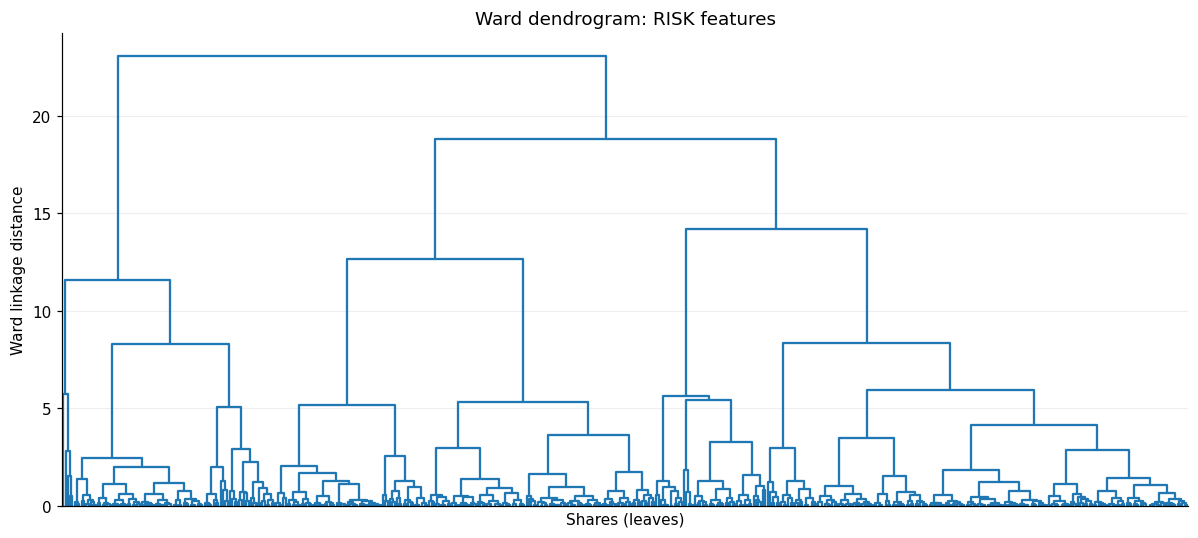

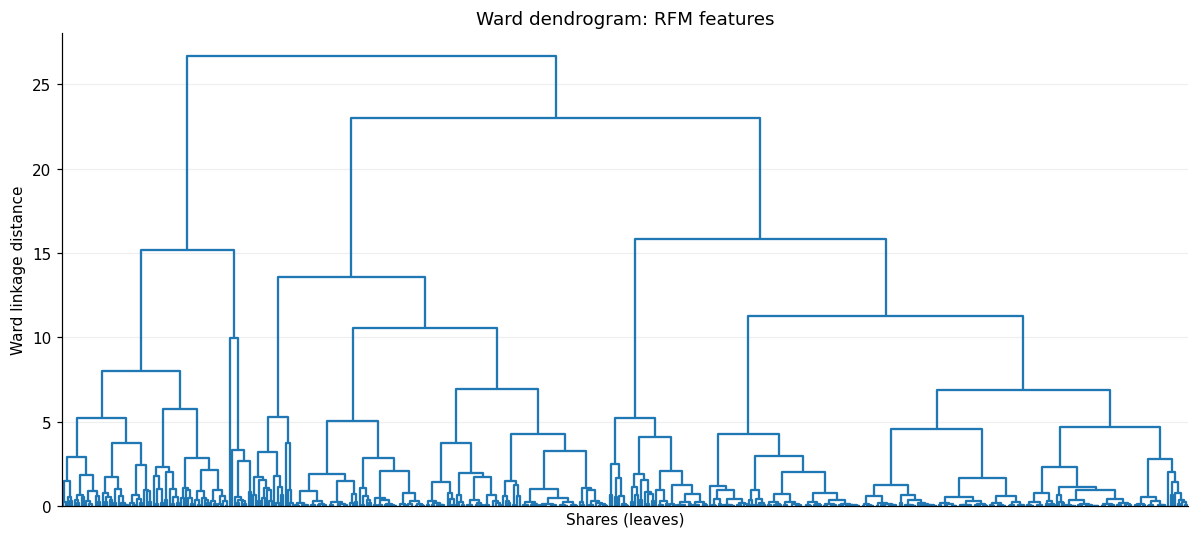

,FeatureSet,Method,K,Silhouette,MinClusterSize,MaxClusterSize,Selected
0,risk,Ward,2,0.3395,92,394,True
1,risk,Ward,3,0.2738,92,230,False
2,risk,Ward,4,0.2821,48,182,False
3,risk,Ward,5,0.3041,48,182,False
4,risk,Ward,6,0.3204,5,182,False
5,risk,Ward,7,0.3240,5,160,False
6,risk,Ward,8,0.3208,5,160,False
7,rfm,Ward,2,0.3680,82,404,True
8,rfm,Ward,3,0.3040,82,250,False
9,rfm,Ward,4,0.2888,43,207,False


,FeatureSet,Method,K,Cluster,Size,MeanWeeklyReturn,WeeklyBeta,R,F,M
0,risk,Ward,2,0,394,0.0020,0.8979,19.6447,2.9416,3.020963e+10
1,risk,Ward,2,1,92,0.0063,1.2981,23.6739,3.1957,7.878092e+10
2,risk,Ward,3,0,230,0.0015,1.1096,18.9304,3.0565,3.380100e+10
3,risk,Ward,3,1,92,0.0063,1.2981,23.6739,3.1957,7.878092e+10
4,risk,Ward,3,2,164,0.0029,0.6012,20.6463,2.7805,2.517294e+10
...,...,...,...,...,...,...,...,...,...,...
65,rfm,Ward,8,3,43,0.0028,1.0081,16.8372,5.3721,1.496218e+10
66,rfm,Ward,8,4,141,0.0025,0.9223,11.1702,3.4468,1.121211e+10
67,rfm,Ward,8,5,18,0.0053,1.3512,17.5000,4.5556,3.504407e+11
68,rfm,Ward,8,6,66,0.0025,0.9336,11.0758,1.8636,1.085987e+10


In [38]:
features, ward_diagnostics, ward_profiles, ward_sizes, ward_labels, ward_candidates = run_clustering(features, 'Ward')
display(ward_diagnostics.drop(columns='Inertia').round(4))
display(ward_candidates.round(4))

### 2.3 K means clustering


K-means groups shares by minimising the sum of squared distances between each share and its cluster centroid. The results can be influenced by the starting centroids, outliers and non-spherical cluster shapes. Each candidate is evaluated using a fixed random seed and 30 initialisations. Silhouette scores, inertia and cluster sizes are compared, and the same selection rule is applied.


In [40]:
features, km_diagnostics, km_profiles, km_sizes, km_labels, km_candidates = run_clustering(features, 'KMeans')
display(km_diagnostics.round(4))
display(km_sizes)
diagnostics = pd.concat([ward_diagnostics, km_diagnostics], ignore_index=True)
profiles = pd.concat([ward_profiles, km_profiles], ignore_index=True)

,FeatureSet,Method,K,Silhouette,Inertia,MinClusterSize,MaxClusterSize,Selected
0,risk,KMeans,2,0.3869,621.6344,143,343,True
1,risk,KMeans,3,0.3289,461.1787,119,202,False
2,risk,KMeans,4,0.3270,371.5771,40,160,False
3,risk,KMeans,5,0.3406,309.6130,27,166,False
4,risk,KMeans,6,0.3349,265.0970,5,156,False
5,risk,KMeans,7,0.3315,227.4762,5,143,False
6,risk,KMeans,8,0.3542,194.3616,5,136,False
7,rfm,KMeans,2,0.4231,1066.8319,68,418,True
8,rfm,KMeans,3,0.3250,796.6144,64,270,False
9,rfm,KMeans,4,0.3409,609.8325,61,212,False


,FeatureSet,Method,K,Cluster,Size
0,risk,KMeans,2,0,143
1,risk,KMeans,2,1,343
2,risk,KMeans,3,0,202
3,risk,KMeans,3,1,165
4,risk,KMeans,3,2,119
...,...,...,...,...,...
65,rfm,KMeans,8,3,66
66,rfm,KMeans,8,4,1
67,rfm,KMeans,8,5,11
68,rfm,KMeans,8,6,140


### 2.4 Cluster profiles and algorithm comparison

Profiles use original units. For RFM, PCA projects the standardised three-dimensional features into two dimensions for display only; clustering uses all three features. The axis labels report variance explained.

,FeatureSet,Method,Cluster,Size,MeanWeeklyReturn,WeeklyBeta,R,F,M
0,risk,Ward,0,394,0.0020,0.8979,19.6447,2.9416,3.020963e+10
1,risk,Ward,1,92,0.0063,1.2981,23.6739,3.1957,7.878092e+10
2,rfm,Ward,0,404,0.0029,0.9666,12.7153,3.1708,3.783020e+10
3,rfm,Ward,1,82,0.0029,1.0089,58.3049,2.0976,4.715898e+10
4,risk,KMeans,0,143,0.0053,1.3505,22.6364,3.1469,8.143839e+10
5,risk,KMeans,1,343,0.0018,0.8166,19.4781,2.9242,2.187973e+10
6,rfm,KMeans,0,418,0.0028,0.9723,13.4234,3.1866,3.269100e+10
7,rfm,KMeans,1,68,0.0030,0.9823,63.3382,1.7794,8.067057e+10


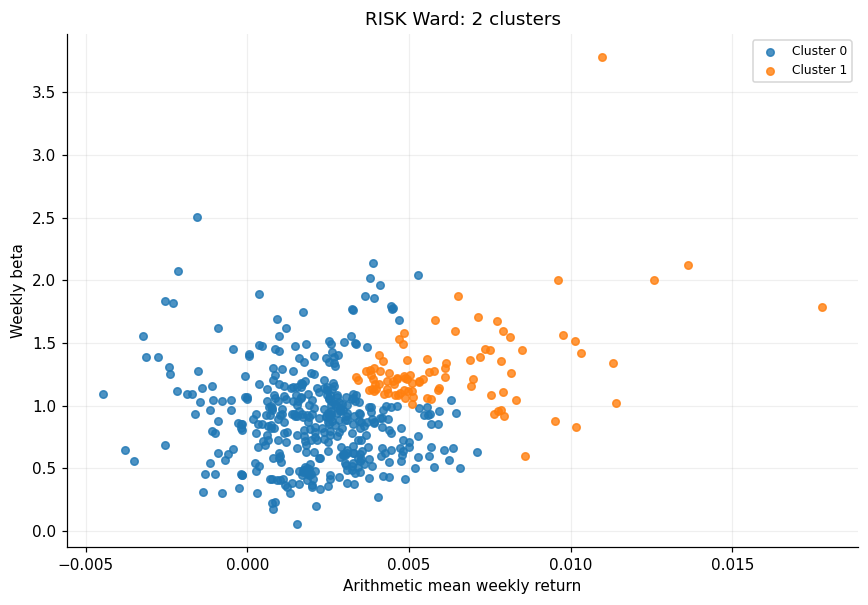

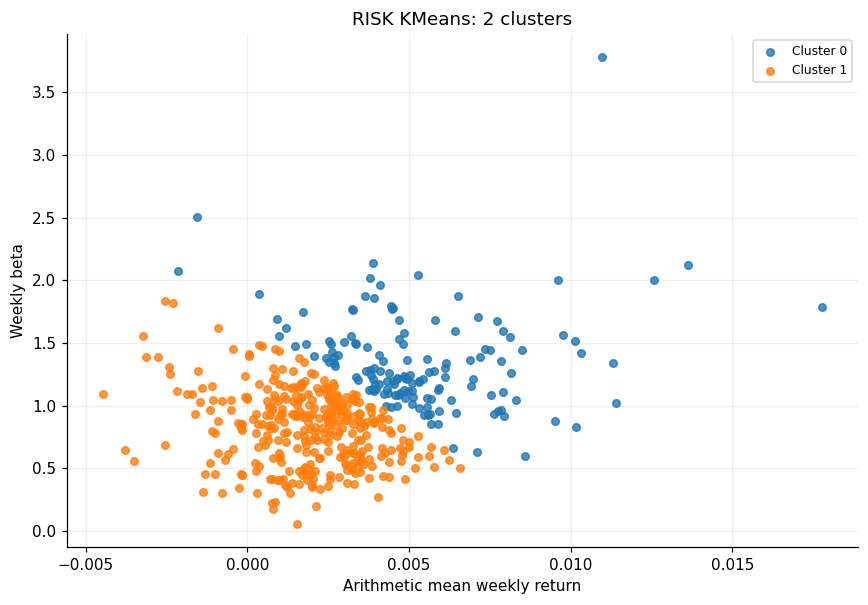

RISK algorithm agreement (ARI): 0.5976


risk_kmeans,0,1
risk_ward,,
0,51,343
1,92,0


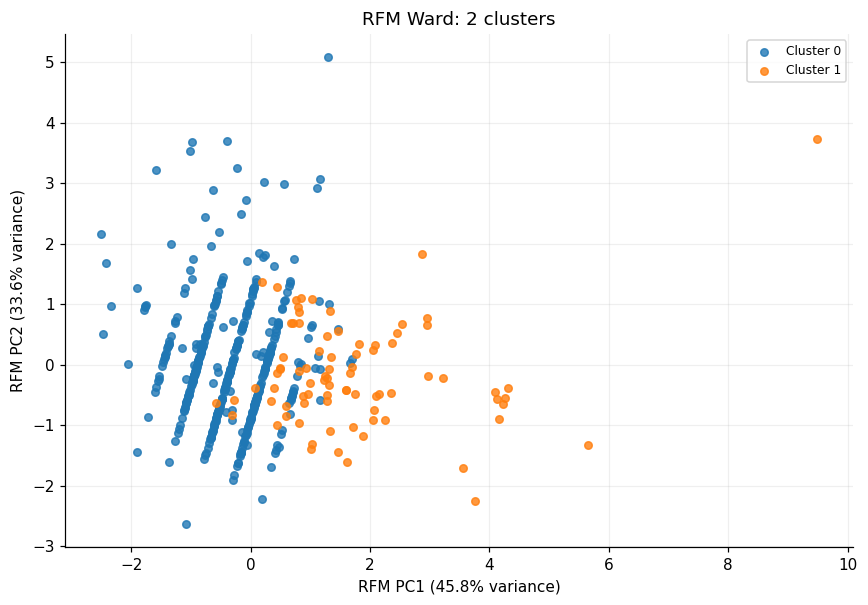

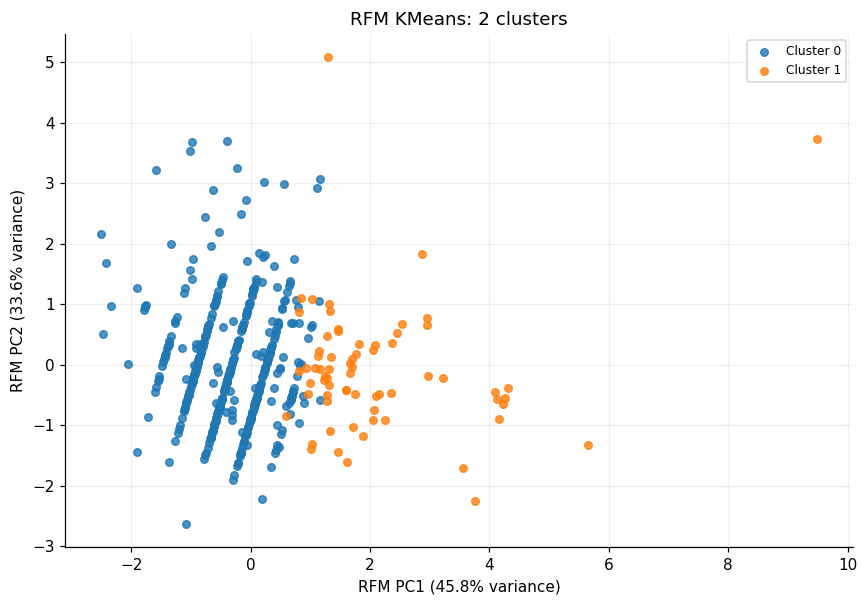

RFM algorithm agreement (ARI): 0.6998


rfm_kmeans,0,1
rfm_ward,,
0,396,8
1,22,60


In [43]:
display(profiles.round(4))
for kind in ['risk', 'rfm']:
    X, cols = model_matrix(features, kind)
    for method in ['Ward', 'KMeans']:
        key = f'{kind}_{method.lower()}'
        df = features
        y = df[key].to_numpy()
        k = len(np.unique(y))
        fig, ax = plt.subplots(figsize=(8, 5.6))
        if kind == 'risk':
            a = df['MeanWeeklyReturn']
            b = df['WeeklyBeta']
            xlabel = 'Arithmetic mean weekly return'
            ylabel = 'Weekly beta'
        else:
            from sklearn.decomposition import PCA
            pca = PCA(n_components=2)
            proj = pca.fit_transform(X)
            a = proj[:, 0]
            b = proj[:, 1]
            xlabel = f'RFM PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)'
            ylabel = f'RFM PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)'
        for lab in sorted(set(y)):
            ii = y == lab
            ax.scatter(np.asarray(a)[ii], np.asarray(b)[ii], s=24, label=f'Cluster {lab}', alpha=0.8)
        ax.set(xlabel=xlabel, ylabel=ylabel, title=f'{kind.upper()} {method}: {k} clusters')
        ax.legend(fontsize=8)
        show_chart(fig)
    ward = features[f'{kind}_ward']
    kmeans = features[f'{kind}_kmeans']
    print(f'{kind.upper()} algorithm agreement (ARI): {adjusted_rand_score(ward, kmeans):.4f}')
    display(pd.crosstab(ward, kmeans))

### 2.5 RFM sensitivity and correlated inputs

#### 2.5.1 Correlation analysis

In [45]:
corr = features[['R', 'F', 'LogM']].corr()
display(corr.round(4))

,R,F,LogM
R,1.0000,-0.3463,0.1524
F,-0.3463,1.0000,0.0128
LogM,0.1524,0.0128,1.0000




#### 2.5.2 Removal of Monetary
Even after standardisation, correlated features can give shared patterns more weight in Euclidean distance calculations. Whether a feature dominates the clustering solution requires evidence beyond its correlation with other features.

In [46]:
selected_k = features['rfm_ward'].nunique()
rf_matrix = StandardScaler().fit_transform(features[['R', 'F']])
features['rfm_ward_without_m'] = AgglomerativeClustering(n_clusters=selected_k, linkage='ward').fit_predict(rf_matrix)
ari = adjusted_rand_score(features['rfm_ward'], features['rfm_ward_without_m'])
print(f'Adjusted Rand index: {ari:.4f}')
for key in ['rfm_ward', 'rfm_ward_without_m']:
    print(key)
    display(features.groupby(key).agg(Count=('Ticker', 'size'), MeanM=('M', 'mean'),
                                      MedianM=('M', 'median'), MeanR=('R', 'mean'), MeanF=('F', 'mean')))
features.to_csv(OUT / 'feature_table_with_clusters.csv', index=False)
display(features[['Ticker', *metrics, 'risk_ward', 'risk_kmeans', 'rfm_ward', 'rfm_kmeans', 'rfm_ward_without_m']])

Adjusted Rand index: 0.8735
rfm_ward


,Count,MeanM,MedianM,MeanR,MeanF
rfm_ward,,,,,
0,404,3.783020e+10,1.604728e+10,12.715347,3.170792
1,82,4.715898e+10,1.784903e+10,58.304878,2.097561


rfm_ward_without_m


,Count,MeanM,MedianM,MeanR,MeanF
rfm_ward_without_m,,,,,
0,397,3.780680e+10,1.546400e+10,12.302267,3.209068
1,89,4.652963e+10,2.084781e+10,56.561798,2.011236


,Ticker,MeanWeeklyReturn,WeeklyBeta,R,F,M,risk_ward,risk_kmeans,rfm_ward,rfm_kmeans,rfm_ward_without_m
0,MMM,0.001142,0.869079,11,4,2.599146e+10,0,1,0,0,0
1,AOS,0.001991,1.042804,11,2,4.748980e+09,0,1,0,0,0
2,ABT,0.000971,0.583542,11,1,3.523027e+10,0,1,0,0,0
3,ABBV,0.003749,0.425366,11,3,6.837054e+10,0,1,0,0,0
4,ACN,0.002376,1.143300,11,2,5.199430e+10,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
481,XYL,0.001358,1.138380,36,3,1.017679e+10,0,1,1,0,1
482,YUM,0.001807,0.631434,56,1,1.339492e+10,0,1,1,1,1
483,ZBRA,0.001181,1.618418,11,4,8.326927e+09,0,0,0,0,0
484,ZBH,-0.001105,0.798203,11,2,9.609458e+09,0,1,0,0,0


In [48]:
display(pd.crosstab(
    features['rfm_ward'],
    features['rfm_ward_without_m'],
    margins=True,
    margins_name='Total'
))

rfm_ward_without_m,0,1,Total
rfm_ward,,,
0,394,10,404
1,3,79,82
Total,397,89,486


## Task 3: Business Intelligence and Critical Review

### 3.2 Review of results and visualisation

#### 3.2.1 Cluster profiles and sector composition

risk_ward,0,1
Sector,,
Communication Services,15,5
Consumer Discretionary,36,11
Consumer Staples,32,0
Energy,16,4
Financials,61,13
Health Care,56,2
Industrials,57,21
Information Technology,45,29
Materials,20,3


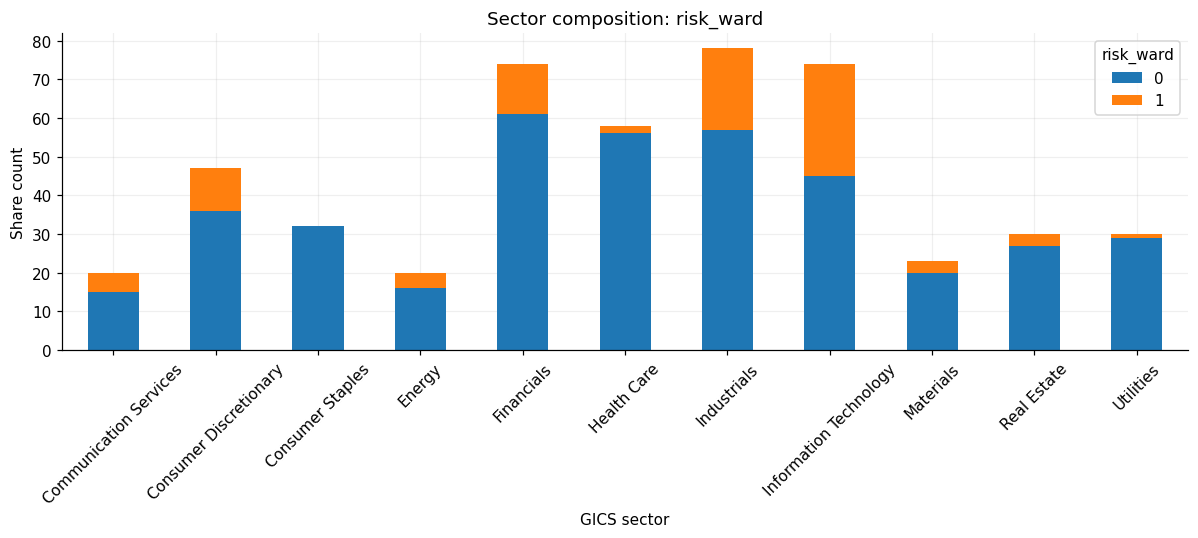

risk_kmeans,0,1
Sector,,
Communication Services,5,15
Consumer Discretionary,23,24
Consumer Staples,1,31
Energy,9,11
Financials,17,57
Health Care,2,56
Industrials,29,49
Information Technology,48,26
Materials,4,19


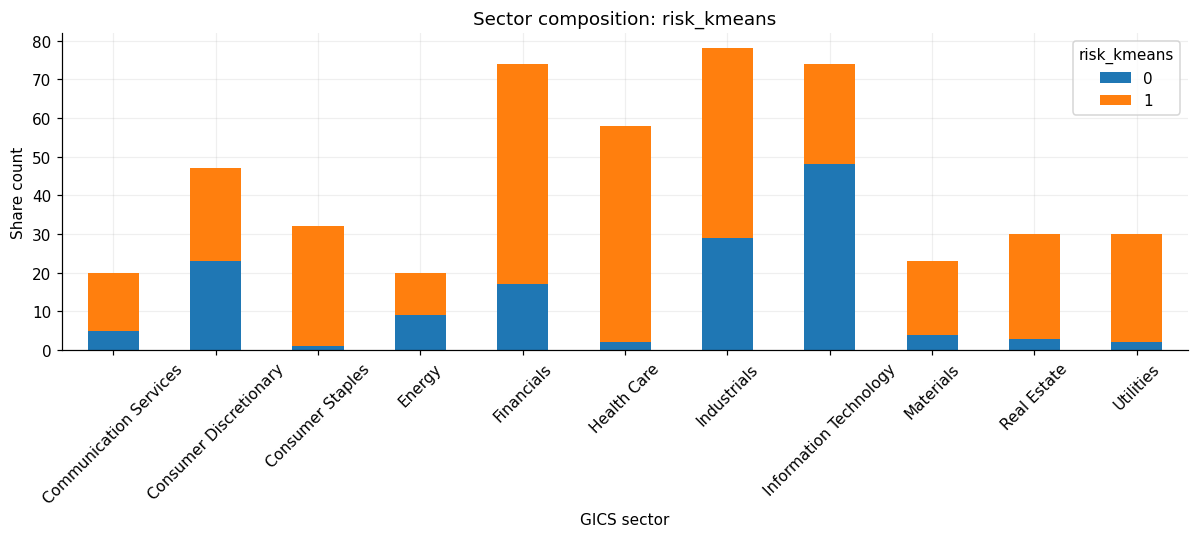

rfm_ward,0,1
Sector,,
Communication Services,16,4
Consumer Discretionary,38,9
Consumer Staples,25,7
Energy,18,2
Financials,64,10
Health Care,49,9
Industrials,72,6
Information Technology,56,18
Materials,15,8


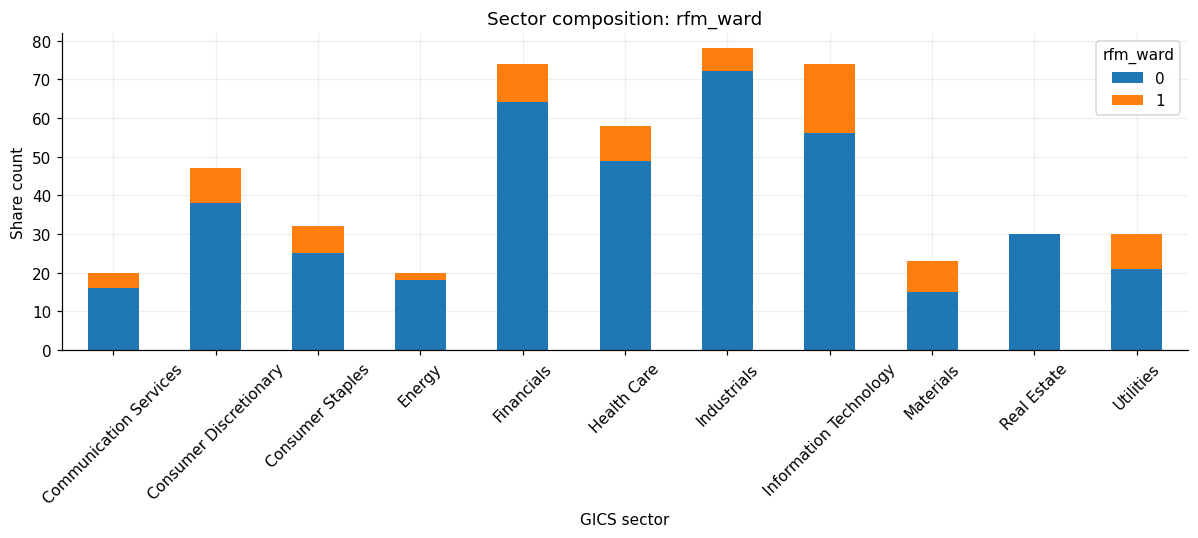

rfm_kmeans,0,1
Sector,,
Communication Services,18,2
Consumer Discretionary,39,8
Consumer Staples,27,5
Energy,19,1
Financials,64,10
Health Care,50,8
Industrials,73,5
Information Technology,60,14
Materials,17,6


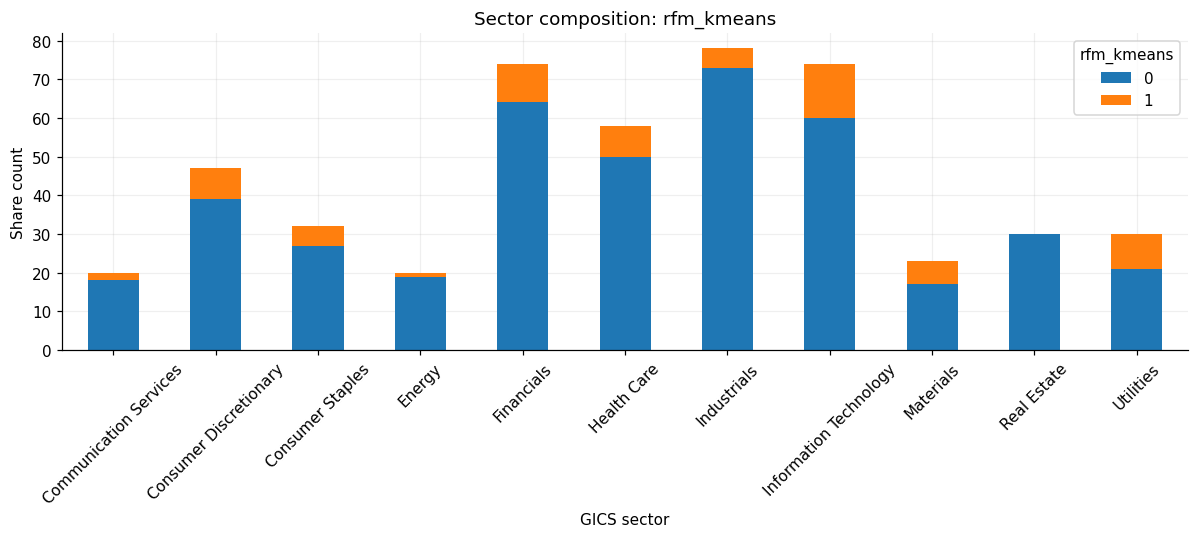

In [50]:
for key in ["risk_ward", "risk_kmeans", "rfm_ward", "rfm_kmeans"]:
    sector = pd.crosstab(features.Sector, features[key])
    display(sector)
    fig, ax = plt.subplots(figsize=(11, 5))
    sector.plot.bar(stacked=True, ax=ax, rot=45)
    ax.set(title=f"Sector composition: {key}", xlabel="GICS sector", ylabel="Share count")
    show_chart(fig)

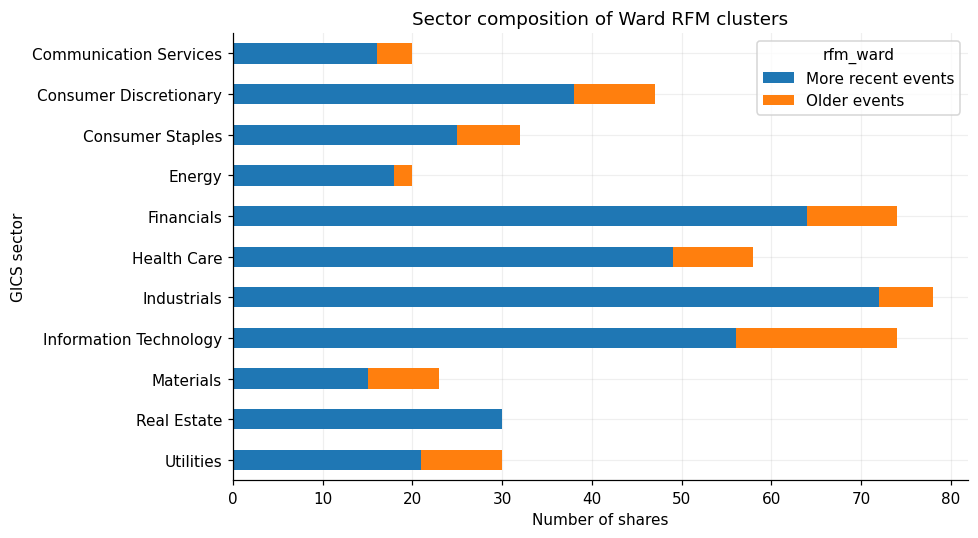

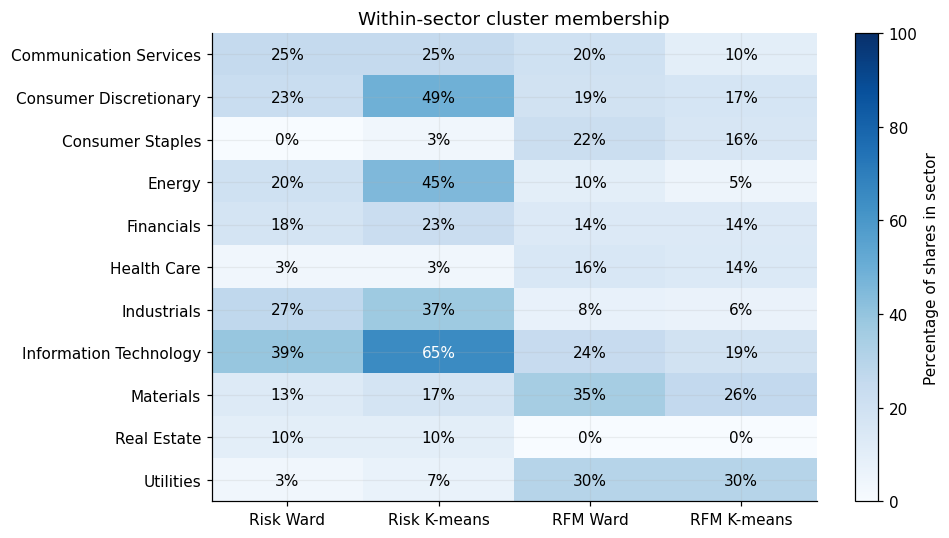

In [53]:
# Figure 7 — counts by sector for Ward RFM
sector_counts = pd.crosstab(features["Sector"], features["rfm_ward"])
sector_counts = sector_counts.rename(columns={
    0: "More recent events",
    1: "Older events",
})

fig, ax = plt.subplots(figsize=(9, 5))
sector_counts.plot.barh(stacked=True, ax=ax)
ax.invert_yaxis()
ax.set(
    title="Sector composition of Ward RFM clusters",
    xlabel="Number of shares",
    ylabel="GICS sector",
)
show_chart(fig)

# Figure 8 — percentage of each sector assigned to the selected group
selected_groups = {
    "Risk Ward": ("risk_ward", 1),
    "Risk K-means": ("risk_kmeans", 0),
    "RFM Ward": ("rfm_ward", 1),
    "RFM K-means": ("rfm_kmeans", 1),
}

sector_pct = pd.DataFrame({
    name: features[column].eq(cluster).groupby(features["Sector"]).mean() * 100
    for name, (column, cluster) in selected_groups.items()
})

fig, ax = plt.subplots(figsize=(9, 5))
heatmap = ax.imshow(sector_pct, cmap="Blues", aspect="auto", vmin=0, vmax=100)
ax.set_xticks(range(len(sector_pct.columns)), labels=sector_pct.columns)
ax.set_yticks(range(len(sector_pct.index)), labels=sector_pct.index)
ax.set_title("Within-sector cluster membership")

for row in range(len(sector_pct.index)):
    for col in range(len(sector_pct.columns)):
        value = sector_pct.iloc[row, col]
        ax.text(col, row, f"{value:.0f}%", ha="center", va="center",
                color="white" if value >= 60 else "black")

fig.colorbar(heatmap, ax=ax, label="Percentage of shares in sector")
show_chart(fig)

## Results export

In [54]:
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink

cluster_keys = ['risk_ward', 'risk_kmeans', 'rfm_ward', 'rfm_kmeans']

tables = {
    'feature_summary': features[metrics].describe(),
    'feature_diagnostics': pd.DataFrame({
        'Skew': features[columns].skew(),
        'IQR outliers': outliers.sum()
    }),
    'risk_standardised': matrices['risk'],
    'rfm_standardised': matrices['rfm'],
    'clustering_diagnostics': diagnostics,
    'ward_candidate_profiles': ward_candidates,
    'kmeans_candidate_sizes': km_sizes,
    'cluster_profiles': profiles,
    'rfm_correlations': corr,
    'rfm_worked_example': example[['Ticker', 'ObservationDate', 'LatestEvent', 'R', 'F', 'M']].to_frame('Value'),
    'rfm_worked_daily_values': worked,
    'rfm_worked_latest_event': evidence.loc[[example.LatestEvent]],
    'rfm_sensitivity_memberships': pd.crosstab(features['rfm_ward'], features['rfm_ward_without_m'])
}

for kind in ['risk', 'rfm']:
    tables[f'{kind}_algorithm_comparison'] = pd.crosstab(
        features[f'{kind}_ward'], features[f'{kind}_kmeans']
    )

for key in cluster_keys:
    tables[f'sector_composition_{key}'] = pd.crosstab(features['Sector'], features[key])

for key in ['rfm_ward', 'rfm_ward_without_m']:
    tables[f'traded_value_{key}'] = features.groupby(key).agg(
        Count=('Ticker', 'size'), MeanM=('M', 'mean'),
        MedianM=('M', 'median'), MeanR=('R', 'mean'), MeanF=('F', 'mean')
    )

keep_index = {
    'feature_summary', 'feature_diagnostics', 'risk_standardised',
    'rfm_standardised', 'rfm_correlations', 'rfm_worked_example',
    'rfm_worked_daily_values', 'rfm_worked_latest_event',
    'rfm_sensitivity_memberships', 'risk_algorithm_comparison',
    'rfm_algorithm_comparison'
}

exported_tables = []
for name, table in tables.items():
    path = OUT / f'{name}.csv'
    table.to_csv(path, index=(name in keep_index or name.startswith(('sector_composition_', 'traded_value_'))))
    exported_tables.append(path)

summary = {
    'observation_date': str(observation_date.date()),
    'constituent_count': int(len(constituents)),
    'included_count': int(len(features)),
    'excluded_count': int((validation['Status'] == 'Excluded').sum()),
    'weekly_observations': int(len(benchmark_returns)),
    'selected_cluster_counts': {key: int(features[key].nunique()) for key in cluster_keys},
    'risk_algorithm_ari': float(adjusted_rand_score(features['risk_ward'], features['risk_kmeans'])),
    'rfm_algorithm_ari': float(adjusted_rand_score(features['rfm_ward'], features['rfm_kmeans'])),
    'rfm_monetary_removal_ari': float(ari)
}
summary_path = OUT / 'results_summary.json'
write_json(summary_path, summary)

required_paths = [
    OUT / 'provenance.json',
    OUT / 'inclusion_exclusion_log.csv',
    OUT / 'feature_table_with_clusters.csv',
    summary_path
]
archive_path = ROOT.parent / '6BUIS017W_CWK1_Results.zip'
archive_files = sorted(DATA.glob('*.csv')) + required_paths + exported_tables + chart_paths
with ZipFile(archive_path, 'w', compression=ZIP_DEFLATED) as archive:
    for path in archive_files:
        archive.write(path, arcname=path.relative_to(ROOT))

try:
    from google.colab import files
except ImportError:
    display(FileLink(archive_path.relative_to(Path.cwd())))
else:
    files.download(str(archive_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>